<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/33_Attention_Mechanisms_%26_Transformers_P2_Attention_Scoring_Functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Attention Scoring Functions and Compatibility Score

We have seen that the decoder uses a **query** $q_t$ to determine which source positions are most relevant.

Each source position has a **key** $k_i$.

To determine how well the query matches a key, attention uses an **attention scoring function**:

$$
e_{t,i} = a(q_t,k_i)
$$

where:

- $q_t$ = query at decoder time step $t$
- $k_i$ = key for source position $i$
- $e_{t,i}$ = compatibility score between the query and that key
- $a(\cdot)$ = attention scoring function

A larger compatibility score means that the key is considered more relevant to the current query.



### Dot-Product Scoring

One simple way to calculate the compatibility score is the **dot product**:

$$
e_{t,i} = q_t^\top k_i
$$

For example, suppose:

$$
q_t =
\begin{bmatrix}
1 \\
2
\end{bmatrix}
\qquad
k_1 =
\begin{bmatrix}
2 \\
1
\end{bmatrix}
$$

Then:

$$
e_{t,1}
=
q_t^\top k_1
=
(1)(2)+(2)(1)
=
4
$$

We repeat this calculation for every key:

$$
e_{t,1}, e_{t,2}, \ldots, e_{t,T}
$$

These are **scores**, not yet attention weights.

We apply **softmax across all of the scores**:

$$
\alpha_{t,i}
=
\frac{\exp(e_{t,i})}
{\sum_{j=1}^{T}\exp(e_{t,j})}
$$

The resulting $\alpha_{t,i}$ values are the **attention weights**.

Softmax exponentiates each score and divides by their total.

Therefore:

`Query + Key → Dot Product → Compatibility Score → Softmax → Attention Weight`

Other options are Scaled dot product,Cosine similarity, and Additive attention.

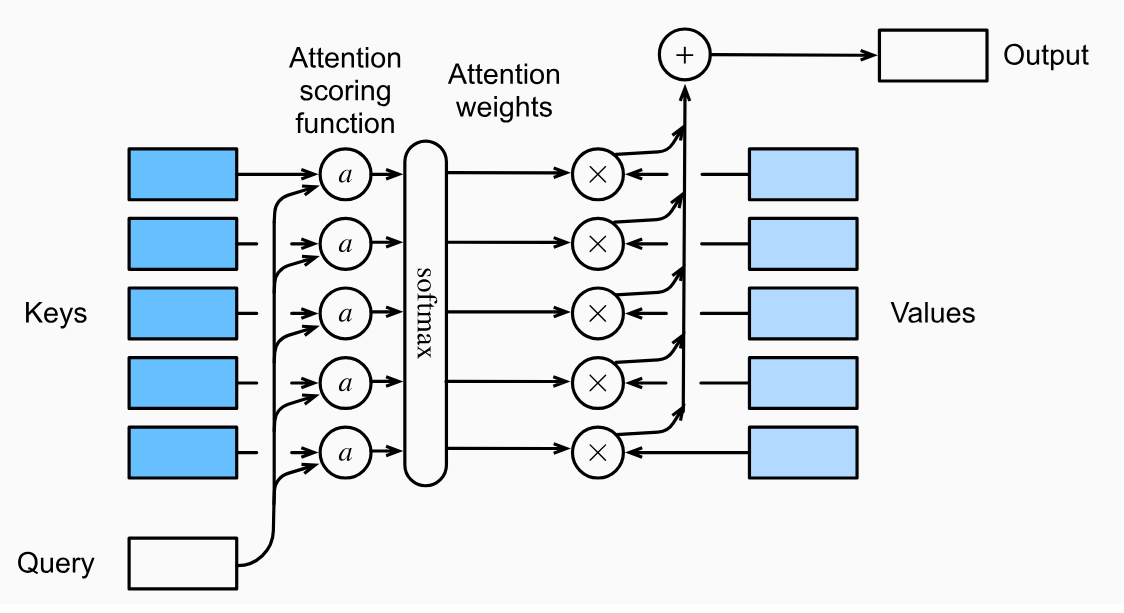



The figure summarizes the complete attention process.

1. The **query** $q$ is compared with each **key** $k_i$ using an attention scoring function:

$$
e_i = a(q,k_i)
$$

For **dot-product attention**:

$$
e_i = q^\top k_i
$$

2. **Softmax is applied to all compatibility scores together** to produce the attention weights:

$$
\alpha_i =
\frac{\exp(e_i)}
{\sum_j \exp(e_j)}
$$

3. Each attention weight multiplies its corresponding **value**:

$$
\alpha_i v_i
$$

4. The weighted values are added to produce the **attention output**:

$$
c = \sum_i \alpha_i v_i
$$



### Masked Softmax

We just saw that attention first calculates a compatibility score for each key:

$$
e_i = q^\top k_i
$$

and then applies softmax to **all of these scores together** to obtain attention weights:

$$
\alpha_i
=
\frac{\exp(e_i)}
{\sum_j \exp(e_j)}
$$

But there is a problem.

In a batch, sequences may have different lengths, so shorter sequences are padded with `<pad>` tokens.

If we apply regular softmax directly, the `<pad>` positions would also receive attention weights even though they contain no useful information.



**Masked softmax solves this problem by excluding padded positions from attention.**

Suppose the compatibility scores are:

$$
[2,\;4,\;1,\;\text{PAD},\;\text{PAD}]
$$

Before softmax, the padded positions are assigned a very large negative value, conceptually:

$$
[2,\;4,\;1,\;-\infty,\;-\infty]
$$

Since:

$$
\exp(-\infty)=0
$$

we obtain:

$$
\operatorname{softmax}
([2,4,1,-\infty,-\infty])
\approx
[0.114,\;0.844,\;0.042,\;0,\;0]
$$

Therefore, the valid positions receive the attention weights, while `<pad>` positions receive zero attention.

In [ ]:
!pip install --q D2l --no-deps

In [ ]:
import tensorflow as tf
from d2l import tensorflow as d2l


### Scaled Dot-Product Attention

We have seen that a simple compatibility score can be calculated using the dot product:

$$
e_i = q^\top k_i
$$

This works well, but there is a potential problem.

When the query and key vectors have **many dimensions**, their dot products can become relatively large.

For example, suppose the query and key each contain $d$ elements:

$$
q =
[q_1,q_2,\ldots,q_d]
$$

$$
k_i =
[k_{i,1},k_{i,2},\ldots,k_{i,d}]
$$

Their dot product is:

$$
q^\top k_i
=
q_1k_{i,1}
+
q_2k_{i,2}
+
\cdots
+
q_dk_{i,d}
$$

As $d$ becomes larger, we are adding more terms, so the resulting dot-product scores can become large in magnitude.

### Why Is That a Problem?

Recall that the compatibility scores are passed through softmax.

For example:

$$
\operatorname{softmax}([1,2,3])
$$

produces a reasonably distributed set of attention weights.

But if the scores become much larger:

$$
\operatorname{softmax}([10,20,30])
$$

softmax becomes extremely concentrated on the largest score.

In other words, one position may receive an attention weight very close to $1$, while the others receive weights very close to $0$.

This can make learning more difficult.





### Scaling the Dot Product

To control the size of the scores, we divide the dot product (compatability score) by the square root of the query/key dimension:

$$
e_i =
\frac{q^\top k_i}{\sqrt{d}}
$$

where:

- $q$ = query vector
- $k_i$ = key vector
- $d$ = number of elements in the query and key vectors

For example, if:

$$
d=4
$$

then:

$$
\sqrt{d}=2
$$

A dot-product score of:

$$
q^\top k_i=8
$$

becomes:

$$
\frac{8}{\sqrt{4}}
=
\frac{8}{2}
=
4
$$

The relative relationships among the scores are preserved, but their magnitudes are reduced before softmax.



Suppose the compatibility scores are:

$$
[1,\;2,\;3]
$$

Applying softmax gives approximately:

$$
[0.09,\;0.24,\;0.67]
$$

The context vector is therefore:

$$
c
=
0.09v_1
+
0.24v_2
+
0.67v_3
$$

All three values contribute, although $v_3$ contributes the most.

Now suppose the scores become much larger:

$$
[10,\;20,\;30]
$$

Softmax gives approximately:

$$
[0.000000002,\;0.000045,\;0.999955]
$$

Now the context vector is approximately:

$$
c \approx v_3
$$

Almost all attention has been placed on a single value.


The attention weights are therefore calculated as:

$$
\alpha_i
=
\operatorname{softmax}
\left(
\frac{q^\top k_i}{\sqrt{d}}
\right)
$$

This is called **scaled dot-product attention**.

The key idea is:

`Query + Key → Dot Product → Scale by √d → Softmax → Attention Weight`

The query and key must have the same dimensionality d so their dot product can be calculated.

### Additive Attention

So far, we have calculated the compatibility between a query and a key using the dot product:

$$
e_{t,i}=q_t^\top k_i
$$

But the dot product requires the query and key to have the **same dimension**.

For example, we cannot directly calculate a dot product if:

$$
q_t=
\begin{bmatrix}
1\\
2
\end{bmatrix}
$$

and:

$$
k_i=
\begin{bmatrix}
2\\
1\\
3
\end{bmatrix}
$$

because the query has 2 elements while the key has 3 elements.

**Additive attention** provides another way to calculate the compatibility score.

Instead of directly multiplying the query and key, the model first transforms them using **learned parameter matrices**:

$$
W_q q_t
$$

and:

$$
W_k k_i
$$

These transformations can produce vectors of the **same dimension**, even when the original query and key have different dimensions.

The transformed vectors are then added:

$$
W_q q_t + W_k k_i
$$

and passed through the $\tanh$ activation function:

$$
\tanh(W_q q_t + W_k k_i)
$$

Finally, another learned vector $w_v$ converts this result into a single compatibility score:

$$
e_{t,i}
=
w_v^\top
\tanh
\left(
W_q q_t + W_k k_i
\right)
$$





### Small Numerical Example

Suppose:

$$
q_t=
\begin{bmatrix}
1\\
2
\end{bmatrix}
$$

and:

$$
k_i=
\begin{bmatrix}
2\\
1\\
3
\end{bmatrix}
$$

Assume the learned transformations produce:

$$
W_q q_t=
\begin{bmatrix}
1\\
2
\end{bmatrix}
$$

and:

$$
W_k k_i=
\begin{bmatrix}
2\\
-1
\end{bmatrix}
$$

Notice that both transformed vectors now have the same dimension.

Add them:

$$
W_q q_t+W_k k_i
=
\begin{bmatrix}
1\\
2
\end{bmatrix}
+
\begin{bmatrix}
2\\
-1
\end{bmatrix}
=
\begin{bmatrix}
3\\
1
\end{bmatrix}
$$

Apply $\tanh$:

$$
\tanh
\left(
\begin{bmatrix}
3\\
1
\end{bmatrix}
\right)
\approx
\begin{bmatrix}
0.995\\
0.762
\end{bmatrix}
$$

Suppose the learned vector is:

$$
w_v=
\begin{bmatrix}
1\\
0.5
\end{bmatrix}
$$

Then the compatibility score is:

$$
e_{t,i}
=
w_v^\top
\begin{bmatrix}
0.995\\
0.762
\end{bmatrix}
$$

$$
e_{t,i}
=
(1)(0.995)+(0.5)(0.762)
$$

$$
e_{t,i}\approx1.376
$$

So:

$$
e_{t,i}\approx1.376
$$

is the compatibility score between this query and this key.

The same calculation is performed for every key:

$$
e_{t,1},e_{t,2},\ldots,e_{t,T}
$$

Then, just as before, **softmax is applied to all of these scores together**:

$$
\alpha_{t,i}
=
\frac{\exp(e_{t,i})}
{\sum_{j=1}^{T}\exp(e_{t,j})}
$$

to obtain the attention weights.



> **What does "learned parameter" mean?**
>
> $W_q$, $W_k$, and $w_v$ are called **learned parameters** because their numerical values are not manually chosen.
>
> We determine their required **shapes**, but their values are learned during training.
>
> They are typically initialized with small random values and then updated through **backpropagation and gradient descent** to reduce the model's loss.
>
> For example:
>
> $$
> W_q =
> \begin{bmatrix}
> 0.2 & -0.1 \\
> 0.4 & 0.3
> \end{bmatrix}
> $$
>
> The numbers $0.2$, $-0.1$, $0.4$, and $0.3$ are parameters that can change during training.
>
> **In short:**  
> `We choose the structure and shape → training learns the values`

### Dot Product vs. Additive Attention

The goal is the same in both methods:

**How compatible is this query with this key?**

Dot-product attention calculates the score directly:

$$
q_t^\top k_i
$$

Additive attention **learns how to combine the query and key** before producing the score:

$$
w_v^\top
\tanh
\left(
W_q q_t+W_k k_i
\right)
$$

In both cases:

`Query + Key → Compatibility Score → Softmax → Attention Weight`

### Summary

We now know two ways to calculate attention compatibility scores:

**Dot-product attention:**

$$
e_{t,i}=q_t^\top k_i
$$

**Additive attention:**

$$
e_{t,i}
=
w_v^\top
\tanh
\left(
W_q q_t + W_k k_i
\right)
$$

Additive attention gives the model a **learned nonlinear way** to determine how well a query matches a key.

Now we return to our Seq2Seq model.


### What Comes Next?

We have now seen how **additive attention** provides a learned way to calculate compatibility between a query and a key:

$$
e_{t,i}
=
w_v^\top
\tanh
\left(
W_q q_t + W_k k_i
\right)
$$

But how can we use this idea to improve the **Seq2Seq model** we studied earlier?

Recall that basic Seq2Seq relies on a **fixed encoder representation** to provide source information to the decoder.

**Bahdanau attention** addresses this limitation by allowing the decoder to attend to different encoder outputs at each decoding step.

Next, we will see how **Bahdanau attention brings additive attention into the Seq2Seq encoder–decoder architecture**.